[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/07-features.ipynb)

# Feature Engineering

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Turn domain hypotheses into features and build one by hand.</li>
<li>Recognise ratio blow-ups and informative missingness in real data.</li>
<li>Write and run a time-travel test that catches features using the future.</li>
<li>Measure what each feature group adds, with a paired interval, and report it honestly.</li>
</ul>
</div>

**Prerequisites:** <a href="../06-baselines/">Baselines</a>. **Dataset:** Online Retail II. **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

On the baselines page, one lesson was loud: the *decision rule* mattered far more than the model. A fair next question is whether better **inputs** help. Feature engineering is where domain knowledge enters a model, and it is also where the most dangerous bugs live, because a feature that accidentally contains the future makes everything look wonderful.

This page does three things: builds features from hypotheses, builds a **test that catches future-peeking**, and then measures honestly how much the extra features are worth. The answer is humbling, and worth knowing.

## Features are hypotheses

Each feature should be a sentence that begins "customers who ...". The set in `mlp_data.retail` (the `features="full"` option) comes from such sentences:

| Group | Features | Hypothesis |
|---|---|---|
| **Basics** | recency, frequency, past-year spend | recent, frequent, big buyers come back (Page 4) |
| **Windows and trend** | orders in the last 30 / 90 / 180 days, previous 90 days, 90-day change, 90-day spend | *recent* behaviour matters more than the whole year; slowing down is a warning |
| **Rhythm** | average gap between orders, recency divided by that gap | a customer who orders monthly is "overdue" after 60 days; one who orders yearly is not |
| **Basket** | average order value, items per order, distinct products | big-basket wholesalers behave differently from occasional shoppers |
| **Returns** | number of returns, share of spend returned | returns signal engagement or dissatisfaction |
| **Tenure, country** | days since first order, UK or not | new customers are different; location may matter |

## Build one by hand: "overdue"

The most interesting is the *overdue ratio*: how long the customer has been silent, compared with how often they normally buy. Build it step by step for the validation snapshot, then confirm it matches the tested module.

In [2]:
cleaned = retail.clean_retail(load_retail())
sales, returns = cleaned.sales, cleaned.returns
cut = retail.VALID_CUTOFF
day = pd.Timedelta(days=1)

inv = retail.invoices(sales)
window = inv[(inv["date"] < cut) & (inv["date"] >= cut - 365 * day)].sort_values("date")   # past year, strictly before the cutoff

gaps = window.groupby("customer_id")["date"].diff().dt.total_seconds() / 86400            # days between consecutive orders
avg_gap = gaps.groupby(window["customer_id"]).mean()
recency = (cut - window.groupby("customer_id")["date"].max()).dt.total_seconds() / 86400
overdue = recency / avg_gap
n_inf = int(np.isinf(overdue).sum())
print(f"{n_inf} customer(s) have an average gap of exactly zero (invoices in the same minute), so the ratio is infinite; we treat that as missing")
overdue = overdue.replace([np.inf, -np.inf], np.nan)

module = retail.make_snapshot(sales, returns, cut, features="full")
assert np.allclose(overdue.reindex(module.index), module["recency_over_gap"], equal_nan=True)
print("matches mlp_data.retail for every customer")
pd.DataFrame({"recency (days)": recency, "average gap (days)": avg_gap, "overdue ratio": overdue}).dropna().head(5)

1 customer(s) have an average gap of exactly zero (invoices in the same minute), so the ratio is infinite; we treat that as missing
matches mlp_data.retail for every customer


,recency (days),average gap (days),overdue ratio
customer_id,,,
12347,54.55,52.62,1.04
12348,56.55,63.28,0.89
12352,70.33,26.05,2.70
12353,12.26,204.21,0.06
12356,53.48,44.78,1.19


A ratio above 1 means "later than usual". It is a clean idea, but ratios are fragile. Look at what real data does to it.

In [3]:
f = module[["recency_over_gap", "avg_order_value", "items_per_order", "monetary"]]
print(f"{module['recency_over_gap'].isna().mean():.0%} of customers have no overdue ratio at all (one order, so no rhythm)")
f.describe(percentiles=[0.5, 0.99]).T[["count", "50%", "99%", "max"]].map("{:,.1f}".format)

36% of customers have no overdue ratio at all (one order, so no rhythm)


,count,50%,99%,max
recency_over_gap,"2,761.0",1.1,"64,634.6","523,564.0"
avg_order_value,"4,324.0",286.7,"1,745.4","14,844.8"
items_per_order,"4,324.0",154.0,"1,350.0","87,167.0"
monetary,"4,324.0",642.9,"17,419.2","252,425.5"


Two problems, both real.

1. **Blow-ups.** The overdue ratio's 99th percentile is in the tens of thousands and its maximum above half a million. A customer who places several invoices within minutes of each other has an average gap near zero, so dividing by it explodes (and for exactly one customer here it is infinite). The same heavy tail appears in spend and basket size.
2. **Missingness is information.** More than a third of customers have **no** rhythm because they ordered once. That is not random noise to patch over; it *means* "new or occasional customer".

**What to do.** Tree-based models do not mind the tail (they only compare order) and handle missing values natively, so for them the stored features are fine. A linear model would need the tail tamed and the gap left-censored; we do that *inside the model's pipeline* with a log transform, a floor on the gap and a missing-value indicator, rather than editing the stored features, so every model sees the same raw facts.

## The test that catches future-peeking

A feature is **point-in-time correct** if it could have been computed on the snapshot date. That has a precise, testable consequence: **if we delete every record from the cutoff onward, the feature must not change.** If it does, it was using the future.

We can turn that into a function and run it on any feature builder.

In [4]:
def time_travel_test(build_features, cutoff):
    """True if features are unchanged when all data from the cutoff onward is deleted."""
    cutoff = pd.Timestamp(cutoff)
    everything = build_features(sales, returns, cutoff)
    past_only = build_features(sales[sales["invoice_date"] < cutoff], returns[returns["invoice_date"] < cutoff], cutoff)
    return everything.equals(past_only)

def course_features(s, r, c):
    return retail.make_snapshot(s, r, c, features="full").drop(columns="y")       # the label is allowed to differ; features are not

print("course features pass the time-travel test:", time_travel_test(course_features, cut))

course features pass the time-travel test: True


Now prove the test can fail. Here is a plausible-looking feature with a one-line bug: "orders in the next 30 days", perhaps written by someone who meant *the last* 30 days.

In [5]:
def buggy_features(s, r, c):
    f = course_features(s, r, c)
    inv_ = retail.invoices(s)
    nxt = inv_[(inv_["date"] >= c) & (inv_["date"] < c + 30 * day)].groupby("customer_id").size()     # BUG: looks forward, not back
    f["orders_30d"] = nxt.reindex(f.index).fillna(0)
    return f

print("buggy feature passes the time-travel test:", time_travel_test(buggy_features, cut))

buggy feature passes the time-travel test: False


<div class="admonition tip">
<p class="admonition-title">Make this a permanent test</p>
<p>The time-travel test is cheap, general, and catches the most expensive class of bug. Run it on every feature set, on a few cutoffs, <strong>in your test suite</strong>. This course's own feature code has exactly such a unit test.</p>
</div>

## How much are the features worth? Measure it

Add the groups one at a time and watch the validation scores. We use one fixed, modest gradient-boosted model for every row, so the *only* thing that changes is the inputs. For the revenue column we rank customers by value at risk (the winning rule from the baselines page).

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from mlp_data.metrics import at_risk_report, bootstrap_difference

sp = retail.build_splits(sales, returns, features="full")
train, valid = sp.train, sp.valid

groups = {
    "basics (recency, frequency, spend)": ["recency_days", "frequency", "monetary"],
    "+ windows and trend":   ["freq_30d", "freq_90d", "freq_180d", "freq_prev_90d", "trend_90d", "monetary_90d"],
    "+ rhythm (gap, overdue)": ["avg_gap_days", "recency_over_gap"],
    "+ basket":              ["avg_order_value", "items_per_order", "n_products"],
    "+ returns":             ["n_returns", "return_value_share"],
    "+ tenure and country":  ["tenure_days", "is_uk"],
}
make_model = lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0, random_state=0)

used, rows, scores = [], {}, {}
for name, cols in groups.items():
    used += cols
    p = make_model().fit(train[used], train["y"]).predict_proba(valid[used])[:, 1]
    scores[name] = p
    quality = at_risk_report(valid["y"], p, valid["monetary"], probabilities=True)                                    # ranking and calibration
    money = at_risk_report(valid["y"], p, valid["monetary"], risk=(1 - p) * valid["monetary"], probabilities=True)   # call the highest value at risk
    rows[name] = {"features": len(used), "AUC": quality["AUC"], "Brier": quality["brier"], "revenue@200 % of oracle": money["revenue@200 % of oracle"]}
ablation = pd.DataFrame(rows).T
ablation.assign(**{"AUC": ablation["AUC"].map("{:.3f}".format), "Brier": ablation["Brier"].map("{:.4f}".format),
                   "revenue@200 % of oracle": ablation["revenue@200 % of oracle"].map("{:.1%}".format), "features": ablation["features"].astype(int)})

,features,AUC,Brier,revenue@200 % of oracle
"basics (recency, frequency, spend)",3,0.792,0.1719,63.2%
+ windows and trend,9,0.795,0.1711,64.4%
"+ rhythm (gap, overdue)",11,0.797,0.1704,63.6%
+ basket,14,0.796,0.1704,64.8%
+ returns,16,0.796,0.1710,65.2%
+ tenure and country,18,0.800,0.1686,64.2%


Each row *adds* a group to everything above it. Read the AUC column from top to bottom: it barely moves. The revenue column drifts up about a point. Is that real, or noise? Compare the first and last rows on the **same customers** with a paired bootstrap.

In [7]:
first, last = "basics (recency, frequency, spend)", "+ tenure and country"
v = valid["monetary"].to_numpy()
auc_diff = bootstrap_difference(valid["y"], v, 1 - scores[last], 1 - scores[first], metric="AUC", n_boot=300, seed=0)
rev_diff = bootstrap_difference(valid["y"], v, (1 - scores[last]) * v, (1 - scores[first]) * v, metric="revenue@200", n_boot=300, seed=0)
pd.DataFrame({"mean difference": [auc_diff["mean"], rev_diff["mean"]],
              "90% interval": [f"{auc_diff['low']:+.4f} to {auc_diff['high']:+.4f}", f"{rev_diff['low']:+,.0f} to {rev_diff['high']:+,.0f}"],
              "full features better in": [f"{auc_diff['share_a_better']:.0%} of resamples", f"{rev_diff['share_a_better']:.0%} of resamples"]},
             index=["AUC", "revenue@200 (pounds)"])

,mean difference,90% interval,full features better in
AUC,0.01,+0.0022 to +0.0121,99% of resamples
revenue@200 (pounds),"7,678.96","-25,442 to +43,957",61% of resamples


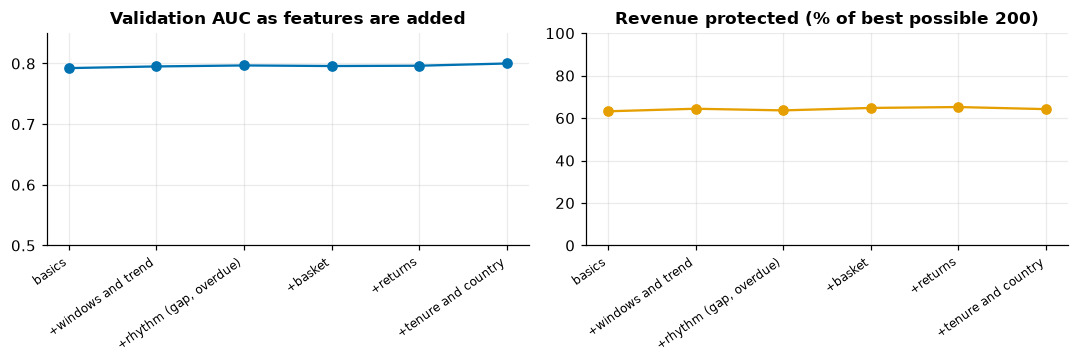

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(ablation)); labels = [n.replace("basics (recency, frequency, spend)", "basics").replace("+ ", "+") for n in ablation.index]
a.plot(x, ablation["AUC"], marker="o", color=style.BLUE); a.set_xticks(x, labels, rotation=35, ha="right", fontsize=8); a.set(title="Validation AUC as features are added", ylim=(0.5, 0.85))
b.plot(x, ablation["revenue@200 % of oracle"] * 100, marker="o", color=style.ORANGE); b.set_xticks(x, labels, rotation=35, ha="right", fontsize=8); b.set(title="Revenue protected (% of best possible 200)", ylim=(0, 100))
plt.tight_layout(); plt.show()

assert ablation["AUC"].max() - ablation["AUC"].iloc[0] < 0.02        # the claim in the text: extra features add very little AUC

**Reading the result.** Adding five groups of carefully reasoned features raises AUC by about nine thousandths, and the paired interval says that gain is **real in direction** (it stays above zero). In money the story is weaker: the revenue protected moves by roughly a percentage point, and its paired interval **includes zero** (the full set comes out ahead in only about three resamples in five). So the honest summary is a small, real gain in *ranking* and **no demonstrable gain in money**. Both are tiny next to the *decision-rule* effect on the baselines page, which was worth tens of points. Statistically detectable is not the same as practically important, and here the money effect is not even detectable.

This is a real and common outcome, and it is worth saying plainly:

<div class="admonition warning">
<p class="admonition-title">Effort is not value</p>
<p>The three basic numbers already carried nearly all the usable signal. Every additional feature is something to compute, test for leakage, monitor for drift and explain, forever. A feature has to <em>earn</em> its keep. "It seemed sensible" is a hypothesis, and here the data mostly said "not much".</p>
</div>

**Our decision.** We keep the full set for the modelling page, because it is harmless, slightly better at ranking, and lets us test models that exploit it. But we record the honest value of the engineering (small, and unproven in money) and we know that if the pipeline ever needs simplifying, the basics-only model is nearly as good.

## Check yourself

<details class="question">
<summary>1. State the time-travel test in one sentence, and say why it catches leakage.</summary>

A feature built for cutoff *c* must be unchanged if all data from *c* onward is deleted. A feature that uses the future depends on that deleted data, so its value changes and the test fails; a legitimately past-only feature cannot change.

</details>

<details class="question">
<summary>2. 36% of customers have no average gap. Why is it better to keep that missingness than to fill it with the average gap?</summary>

Missing here *means* "ordered once", which is itself predictive (new and occasional customers behave differently). Filling in an average hides that fact and invents a rhythm that does not exist. Tree models use the missing pattern directly; linear models should get a separate "has rhythm" indicator alongside any filled value.

</details>

<details class="question">
<summary>3. The extra features gave a tiny gain. Is the feature work wasted?</summary>

Not wasted: it produced a measured answer (small), a leakage test we will reuse, and a feature set whose behaviour we understand. The mistake would be to *assume* it helped without measuring, or to keep adding features because effort felt like progress. Report the gain honestly, and weigh it against the cost of maintaining each feature.

</details>

## Exercise

<details class="question">
<summary>Add <code>spend_per_day_of_tenure = monetary / tenure_days</code>. Guard against dividing by zero, run the time-travel test, and check whether it changes the validation AUC.</summary>

```python
def with_new_feature(s, r, c):
    f = course_features(s, r, c)
    f["spend_per_day"] = f["monetary"] / f["tenure_days"].clip(lower=1)     # clip: a customer first seen today has tenure ~ 0
    return f

print("passes time-travel:", time_travel_test(with_new_feature, cut))      # True: both ingredients are past-only

ratio = lambda d: d["monetary"] / d["tenure_days"].clip(lower=1)           # same formula on the ready-made tables
cols = [c for c in train.columns if c not in ("customer_id", "cutoff", "y")]
for name, extra in [("without", []), ("with", ["spend_per_day"])]:
    tr, va = train.assign(spend_per_day=ratio(train)), valid.assign(spend_per_day=ratio(valid))
    p = make_model().fit(tr[cols + extra], tr["y"]).predict_proba(va[cols + extra])[:, 1]
    print(name, round(at_risk_report(va["y"], p, va["monetary"])["AUC"], 4))
```

It passes the time-travel test (both ingredients only use the past), and the validation AUC does **not** improve: it moves by about three thousandths, in the wrong direction. A ratio of two features the model already has adds nothing a tree cannot already learn. A good outcome for an exercise is not "the feature helped", it is "I tested it properly and know".

</details>

## Recap

- Write each feature as a hypothesis ("customers who ..."), then test it. Plausible is not proven.
- Real data breaks ratios (division by near-zero) and carries information in what is **missing**.
- The **time-travel test** (delete everything from the cutoff on; the features must not change) is a cheap, general guard against the costliest bug. Prove it can fail, then keep it in your test suite.
- Measure what each group adds, on the same customers, with an interval. Here five groups added very little: **effort is not value**.
- Keep features that earn their keep, and remember each one has an ongoing cost.

**Next:** *Modelling*, where we compare model families fairly on these features.